<a href="https://colab.research.google.com/github/twinkle-treesa/Product-Return-Prediction/blob/main/Ecommerce_Product_Return_No_Curve_Graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Product Return Prediction

Section 1 — Install Required Libraries


In [ ]:
# ============================================================
# SECTION 1. INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install seaborn joblib scikit-learn pandas numpy matplotlib


Section 2 — Import Libraries and Set Configuration


In [ ]:
# ============================================================
# SECTION 2. IMPORT LIBRARIES
# ============================================================

import os
import json
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_curve,
    ConfusionMatrixDisplay, precision_recall_fscore_support
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
OUTPUT_DIR = Path('return_prediction_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)

print('Libraries imported successfully.')
print('Output directory:', OUTPUT_DIR.resolve())


Libraries imported successfully.
Output directory: /content/return_prediction_outputs


Section 3 — Upload and Load the Updated Signal-Demo 64/36 Dataset


In [ ]:
# ============================================================
# SECTION 3. UPLOAD AND LOAD DATASET
# ============================================================

uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith('.csv')]
if not csv_files:
    raise ValueError('Please upload the updated CSV dataset.')

# Prefer the signal-demo dataset if multiple CSV files are uploaded.
signal_demo_files = [
    name for name in csv_files
    if 'signal_demo_with_return_reason' in name.lower()
]
standard_64_36_files = [
    name for name in csv_files
    if '64_36_with_return_reason' in name.lower()
    and 'signal_demo' not in name.lower()
]

if signal_demo_files:
    DATA_PATH = signal_demo_files[0]
elif standard_64_36_files:
    DATA_PATH = standard_64_36_files[0]
else:
    DATA_PATH = csv_files[0]

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.astype(str).str.strip()

print('Dataset loaded:', DATA_PATH)
print('Rows and columns:', df.shape)
print('Note: target labels and return reasons in the signal-demo dataset are synthetic.')
print('Target balance:')
display(df['returned'].value_counts(dropna=False).to_frame('count'))
print('Target balance percentages:')
display((df['returned'].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame('percentage'))
print('\nFirst five records:')
display(df.head())
print('\nColumn names:')
print(df.columns.tolist())


Saving ecommerce_product_return_model_ready_64_36_signal_demo_with_return_reason.csv to ecommerce_product_return_model_ready_64_36_signal_demo_with_return_reason.csv
Dataset loaded: ecommerce_product_return_model_ready_64_36_signal_demo_with_return_reason.csv
Rows and columns: (30000, 42)
Note: target labels and return reasons in the signal-demo dataset are synthetic.
Target balance:


,count
returned,
No,19200
Yes,10800


Target balance percentages:


,percentage
returned,
No,64.0
Yes,36.0



First five records:


,order_month,order_weekday,category,subcategory,brand_tier,price,quantity,discount_pct,total_amount,shipping_cost,payment_method,region,customer_city_tier,customer_age,customer_gender,customer_segment,account_age_months,previous_orders_count,customer_previous_return_rate_pct,customer_purchase_frequency,product_rating,product_review_count,product_review_sentiment,product_quality_score,product_defect_rate_pct,description_match_score,image_accuracy_score,size_fit_risk,seller_rating,seller_historical_return_rate_pct,seller_fulfillment_score,packaging_quality_score,estimated_delivery_days,shipping_speed,return_window_days,promotion_type,sales_channel,device_type,is_gift,product_weight_kg,returned,return_reason
0,2,6,Grocery,Household Staples,Mid-range,1.57,1,58.57,1.00,6.19,Credit Card,North,Tier 3,54,Female,At-Risk,70,51,37.97,Frequent,5.00,598,Positive,4.60,2.75,4.15,5.00,Not Applicable,4.22,11.95,4.43,4.18,6,Standard,7,Clearance,Website,iOS,No,0.63,No,NaN
1,8,3,Electronics,Smart Watches,Budget,27.80,1,13.74,23.98,5.73,Debit Card,South,Tier 3,31,Prefer not to say,Regular,42,8,3.29,Regular,3.36,38,Neutral,1.74,11.10,1.95,2.64,Not Applicable,4.15,7.31,4.09,2.30,7,Standard,30,Coupon,Mobile App,iOS,No,0.50,Yes,Not as described
2,12,4,Books & Stationery,Office Supplies,Mid-range,2.50,1,6.48,2.34,4.78,Cash on Delivery,South,Tier 2,18,Male,New,3,2,3.50,Occasional,4.33,51,Positive,3.65,4.00,4.04,4.62,Not Applicable,4.15,16.71,4.16,3.26,3,Express,30,No Promotion,Marketplace,Android,No,0.39,No,NaN
3,6,6,Toys & Games,Dolls,Mid-range,230.66,1,28.07,165.91,4.57,Debit Card,East,Tier 1,67,Female,New,2,0,9.40,Rare,4.16,4,Positive,3.40,4.22,3.91,4.40,Not Applicable,4.47,11.05,4.19,3.88,7,Standard,14,Flash Sale,Marketplace,Desktop,No,0.34,No,NaN
4,2,0,Sports & Outdoors,Outdoor Accessories,Premium,383.97,1,7.71,354.37,3.20,Debit Card,South,Tier 2,29,Female,New,74,0,19.07,Rare,3.19,25,Negative,2.84,7.59,4.02,1.73,Not Applicable,5.00,11.14,4.51,3.09,1,Same Day,30,Seasonal Sale,Social Commerce,Android,No,0.55,Yes,Not as described



Column names:
['order_month', 'order_weekday', 'category', 'subcategory', 'brand_tier', 'price', 'quantity', 'discount_pct', 'total_amount', 'shipping_cost', 'payment_method', 'region', 'customer_city_tier', 'customer_age', 'customer_gender', 'customer_segment', 'account_age_months', 'previous_orders_count', 'customer_previous_return_rate_pct', 'customer_purchase_frequency', 'product_rating', 'product_review_count', 'product_review_sentiment', 'product_quality_score', 'product_defect_rate_pct', 'description_match_score', 'image_accuracy_score', 'size_fit_risk', 'seller_rating', 'seller_historical_return_rate_pct', 'seller_fulfillment_score', 'packaging_quality_score', 'estimated_delivery_days', 'shipping_speed', 'return_window_days', 'promotion_type', 'sales_channel', 'device_type', 'is_gift', 'product_weight_kg', 'returned', 'return_reason']


Section 4 — Initial Dataset Analysis


DATASET INFORMATION
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 42 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   order_month                        30000 non-null  int64  
 1   order_weekday                      30000 non-null  int64  
 2   category                           30000 non-null  object 
 3   subcategory                        30000 non-null  object 
 4   brand_tier                         30000 non-null  object 
 5   price                              30000 non-null  float64
 6   quantity                           30000 non-null  int64  
 7   discount_pct                       30000 non-null  float64
 8   total_amount                       30000 non-null  float64
 9   shipping_cost                      30000 non-null  float64
 10  payment_method             

,missing_count
return_reason,19200
order_month,0
category,0
subcategory,0
brand_tier,0
price,0
quantity,0
discount_pct,0
total_amount,0
order_weekday,0



Exact duplicate rows: 0

Return target counts:


,count
returned,
No,19200
Yes,10800



Return target percentages:


,percentage
returned,
No,64.0
Yes,36.0



Return reasons among returned orders:


,count
return_reason,
Defective,3038
No longer needed,2699
Not as described,2509
Missing/Wrong item,1819
Slow delivery,735


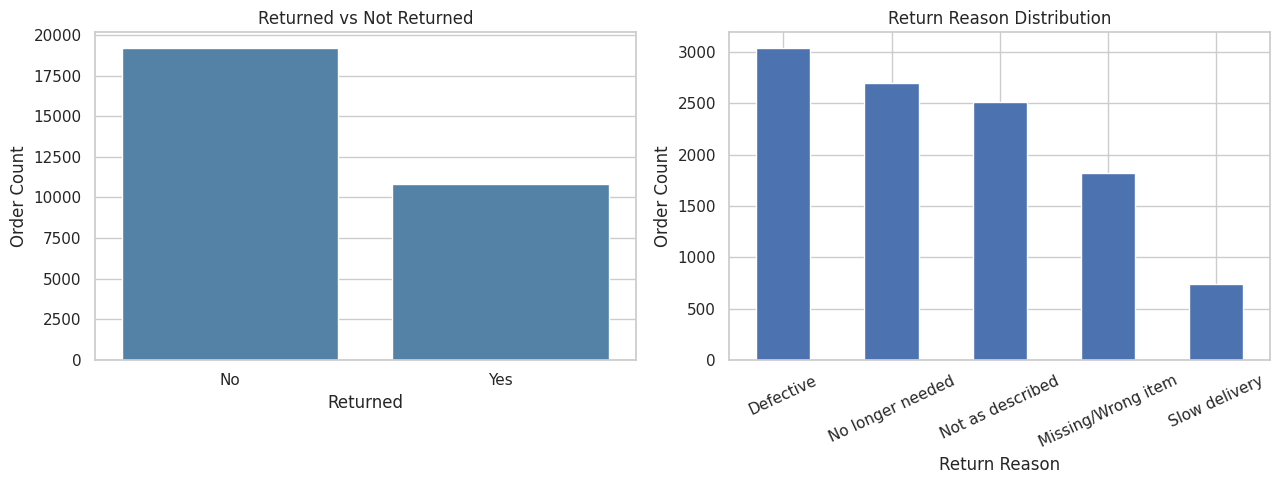

In [ ]:
# ============================================================
# SECTION 4. INITIAL DATASET ANALYSIS
# ============================================================

print('DATASET INFORMATION')
print('-' * 70)
df.info()

print('\nMissing values per column:')
display(df.isna().sum().sort_values(ascending=False).rename('missing_count').to_frame())

print('\nExact duplicate rows:', df.duplicated().sum())

required_columns = {'returned', 'return_reason'}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f'Missing required columns: {sorted(missing_required)}')

print('\nReturn target counts:')
display(df['returned'].value_counts(dropna=False).to_frame('count'))
print('\nReturn target percentages:')
display((df['returned'].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame('percentage'))

print('\nReturn reasons among returned orders:')
returned_mask_preview = df['returned'].astype(str).str.strip().str.lower().eq('yes')
display(df.loc[returned_mask_preview, 'return_reason'].value_counts(dropna=False).to_frame('count'))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x='returned', order=['No', 'Yes'], ax=axes[0], color='steelblue')
axes[0].set_title('Returned vs Not Returned')
axes[0].set_xlabel('Returned')
axes[0].set_ylabel('Order Count')
reason_counts_preview = df.loc[returned_mask_preview, 'return_reason'].dropna().value_counts()
reason_counts_preview.plot(kind='bar', ax=axes[1])
axes[1].set_title('Return Reason Distribution')
axes[1].set_xlabel('Return Reason')
axes[1].set_ylabel('Order Count')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'initial_target_and_reason_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()


Section 5 — Data Cleaning and Feature Engineering


In [ ]:
# ============================================================
# SECTION 5. DATA CLEANING AND FEATURE ENGINEERING
# ============================================================

df = df.copy()

# 5.1 Strip leading and trailing spaces from text columns.
for column in df.select_dtypes(include=['object', 'string']).columns:
    df[column] = df[column].apply(lambda value: value.strip() if isinstance(value, str) else value)

# 5.2 Normalize the binary target labels.
df['returned'] = df['returned'].astype(str).str.strip().str.lower()
df['returned'] = df['returned'].replace({'true': 'yes', 'false': 'no', '1': 'yes', '0': 'no'})
invalid_target = ~df['returned'].isin(['yes', 'no'])
if invalid_target.any():
    raise ValueError(f'Unexpected values in returned: {df.loc[invalid_target, "returned"].unique().tolist()}')

# 5.3 Remove exact duplicate rows.
rows_before_duplicates = len(df)
df = df.drop_duplicates().copy()
print('Duplicate rows removed:', rows_before_duplicates - len(df))

# 5.4 Remove identifiers and fields that are only known after the outcome.
# return_reason is kept in df as a label for the separate reason model, but never as a binary-model input.
columns_to_drop = [
    'order_id', 'customer_id', 'product_id',
    'request_date', 'return_date', 'actual_return_date',
    'refund_amount', 'return_status', 'actual_delivery_days'
]
existing_drop_columns = [column for column in columns_to_drop if column in df.columns]
if existing_drop_columns:
    df.drop(columns=existing_drop_columns, inplace=True)
print('Identifier / post-outcome columns removed:', existing_drop_columns)

# 5.5 Support the older discount column if this notebook is reused on an earlier dataset.
# Current updated dataset already stores discount as discount_pct (e.g. 15 means 15%).
if 'discount_pct' not in df.columns and 'discount' in df.columns:
    old_discount = pd.to_numeric(df['discount'], errors='coerce')
    max_discount = old_discount.dropna().max()
    df['discount_pct'] = old_discount * 100 if pd.notna(max_discount) and max_discount <= 1 else old_discount
    df.drop(columns=['discount'], inplace=True)

# 5.6 Convert known numerical columns safely.
numeric_columns = [
    'order_month', 'order_weekday', 'price', 'quantity', 'discount_pct',
    'total_amount', 'shipping_cost', 'customer_age', 'account_age_months',
    'previous_orders_count', 'customer_previous_return_rate_pct',
    'product_rating', 'product_review_count', 'product_quality_score',
    'product_defect_rate_pct', 'description_match_score', 'image_accuracy_score',
    'seller_rating', 'seller_historical_return_rate_pct', 'seller_fulfillment_score',
    'packaging_quality_score', 'estimated_delivery_days', 'return_window_days',
    'product_weight_kg'
]
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

# 5.7 Derive month and weekday only if working with an older dataset that contains order_date.
if 'order_date' in df.columns:
    order_dates = pd.to_datetime(df['order_date'], errors='coerce', dayfirst=True)
    if 'order_month' not in df.columns:
        df['order_month'] = order_dates.dt.month
    if 'order_weekday' not in df.columns:
        df['order_weekday'] = order_dates.dt.dayofweek
    df.drop(columns=['order_date'], inplace=True)

# 5.8 Harmonize known legacy category labels.
category_mapping = {
    'Home': 'Home & Kitchen',
    'Toys': 'Toys & Games',
    'Sports': 'Sports & Outdoors',
    'Beauty': 'Beauty & Personal Care'
}
if 'category' in df.columns:
    df['category'] = df['category'].replace(category_mapping)

payment_mapping = {'COD': 'Cash on Delivery', 'Wallet': 'Digital Wallet'}
if 'payment_method' in df.columns:
    df['payment_method'] = df['payment_method'].replace(payment_mapping)

# 5.9 Convert is_gift to binary where the values are recognizable.
if 'is_gift' in df.columns:
    gift_map = {'yes': 1, 'no': 0, 'true': 1, 'false': 0, '1': 1, '0': 0}
    gift_values = df['is_gift'].astype('string').str.strip().str.lower()
    gift_mapped = gift_values.map(gift_map)
    if gift_mapped.notna().sum() == gift_values.notna().sum():
        df['is_gift'] = gift_mapped

# 5.10 Feature engineering: absolute discount amount.
if {'price', 'quantity', 'discount_pct'}.issubset(df.columns):
    df['discount_amount'] = (
        df['price'] * df['quantity'] * df['discount_pct'] / 100.0
    )

# 5.11 Feature engineering: shipping cost relative to item price.
if {'shipping_cost', 'price'}.issubset(df.columns):
    safe_price = df['price'].replace(0, np.nan)
    df['shipping_ratio'] = df['shipping_cost'] / safe_price

# 5.12 Feature engineering: paid amount per item.
if {'total_amount', 'quantity'}.issubset(df.columns):
    safe_quantity = df['quantity'].replace(0, np.nan)
    df['amount_per_item'] = df['total_amount'] / safe_quantity

# 5.13 Weekend feature and cyclical encodings for the order calendar.
# Convention: Monday=0 ... Sunday=6.
if 'order_month' in df.columns:
    month = df['order_month']
    df['order_month_sin'] = np.sin(2 * np.pi * (month - 1) / 12)
    df['order_month_cos'] = np.cos(2 * np.pi * (month - 1) / 12)

if 'order_weekday' in df.columns:
    weekday = df['order_weekday']
    df['ordered_is_weekend'] = weekday.isin([5, 6]).astype(int)
    df['order_weekday_sin'] = np.sin(2 * np.pi * weekday / 7)
    df['order_weekday_cos'] = np.cos(2 * np.pi * weekday / 7)

# The cyclical features replace raw month and weekday to avoid treating cycles as linear.
df.drop(columns=[column for column in ['order_month', 'order_weekday'] if column in df.columns], inplace=True)

# 5.14 Keep reason labels only for returned orders; non-returned orders should have no reason.
df['return_reason'] = df['return_reason'].apply(lambda value: value.strip() if isinstance(value, str) else value)
df.loc[df['returned'].eq('no'), 'return_reason'] = np.nan
missing_reasons = df['returned'].eq('yes') & df['return_reason'].isna()
if missing_reasons.any():
    raise ValueError(f'{missing_reasons.sum()} returned records have no return_reason. Correct the dataset before training.')

# 5.15 Replace infinite feature-engineering results with NaN; the pipelines will impute them.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print('\nShape after cleaning / feature engineering:', df.shape)
print('Engineered columns present:', [column for column in [
    'discount_amount', 'shipping_ratio', 'amount_per_item',
    'ordered_is_weekend', 'order_month_sin', 'order_month_cos',
    'order_weekday_sin', 'order_weekday_cos'
] if column in df.columns])
print('Rows with returned=Yes but no reason:', df.loc[df['returned'].eq('yes'), 'return_reason'].isna().sum())
print('\nUpdated target distribution (%):')
print((df['returned'].value_counts(normalize=True) * 100).round(2))


Duplicate rows removed: 0
Identifier / post-outcome columns removed: []

Shape after cleaning / feature engineering: (30000, 48)
Engineered columns present: ['discount_amount', 'shipping_ratio', 'amount_per_item', 'ordered_is_weekend', 'order_month_sin', 'order_month_cos', 'order_weekday_sin', 'order_weekday_cos']
Rows with returned=Yes but no reason: 0

Updated target distribution (%):
returned
no     64.0
yes    36.0
Name: proportion, dtype: float64


Section 6 — Encode Target and Separate Features


In [ ]:
# ============================================================
# SECTION 6. TARGET ENCODING AND FEATURE / TARGET SEPARATION
# ============================================================

# Binary target encoding: No = 0, Yes = 1.
df['returned'] = df['returned'].map({'no': 0, 'yes': 1}).astype(int)


X = df.drop(columns=['returned', 'return_reason']).copy()
y = df['returned'].copy()

# Remove all-empty feature columns; partial missing values are imputed inside each pipeline.
all_missing_columns = X.columns[X.isna().all()].tolist()
if all_missing_columns:
    X.drop(columns=all_missing_columns, inplace=True)
    print('All-empty features removed:', all_missing_columns)

leakage_columns = {'returned', 'return_reason', 'return_date', 'actual_return_date', 'refund_amount'}.intersection(X.columns)
if leakage_columns:
    raise ValueError(f'Potential leakage columns found in X: {sorted(leakage_columns)}')

print('X shape:', X.shape)
print('y shape:', y.shape)
print('\nTarget labels: 0 = Not Returned; 1 = Returned')
print(y.value_counts().sort_index().rename(index={0: 'Not Returned', 1: 'Returned'}))
print('\nTarget percentages:')
print((y.value_counts(normalize=True).sort_index() * 100).round(2).rename(index={0: 'Not Returned', 1: 'Returned'}))
print('\nBinary model input features:')
print(X.columns.tolist())


X shape: (30000, 46)
y shape: (30000,)

Target labels: 0 = Not Returned; 1 = Returned
returned
Not Returned    19200
Returned        10800
Name: count, dtype: int64

Target percentages:
returned
Not Returned    64.0
Returned        36.0
Name: proportion, dtype: float64

Binary model input features:
['category', 'subcategory', 'brand_tier', 'price', 'quantity', 'discount_pct', 'total_amount', 'shipping_cost', 'payment_method', 'region', 'customer_city_tier', 'customer_age', 'customer_gender', 'customer_segment', 'account_age_months', 'previous_orders_count', 'customer_previous_return_rate_pct', 'customer_purchase_frequency', 'product_rating', 'product_review_count', 'product_review_sentiment', 'product_quality_score', 'product_defect_rate_pct', 'description_match_score', 'image_accuracy_score', 'size_fit_risk', 'seller_rating', 'seller_historical_return_rate_pct', 'seller_fulfillment_score', 'packaging_quality_score', 'estimated_delivery_days', 'shipping_speed', 'return_window_days', 'p

Section 7 — Split into Training, Validation, and Test Sets


In [ ]:
# ============================================================
# SECTION 7. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train_val
)

print('Training shape:', X_train.shape)
print('Validation shape:', X_val.shape)
print('Test shape:', X_test.shape)

for split_name, split_y in [('Training', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'\n{split_name} class counts:')
    print(split_y.value_counts().sort_index().rename(index={0: 'Not Returned', 1: 'Returned'}))
    print('Percentages:')
    print((split_y.value_counts(normalize=True).sort_index() * 100).round(2))



Training shape: (18000, 46)
Validation shape: (6000, 46)
Test shape: (6000, 46)

Training class counts:
returned
Not Returned    11520
Returned         6480
Name: count, dtype: int64
Percentages:
returned
0    64.0
1    36.0
Name: proportion, dtype: float64

Validation class counts:
returned
Not Returned    3840
Returned        2160
Name: count, dtype: int64
Percentages:
returned
0    64.0
1    36.0
Name: proportion, dtype: float64

Test class counts:
returned
Not Returned    3840
Returned        2160
Name: count, dtype: int64
Percentages:
returned
0    64.0
1    36.0
Name: proportion, dtype: float64


Section 8 — Common Preprocessing Pipelines


In [ ]:
# ============================================================
# SECTION 8. COMMON PREPROCESSING PIPELINES
# ============================================================

# Determine feature families using only the training set.
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()

print('Numerical feature count:', len(numeric_features))
print('Categorical feature count:', len(categorical_features))
print('\nNumerical features:', numeric_features)
print('\nCategorical features:', categorical_features)


def make_preprocessor(scale_numeric=False):
    """Create a fresh imputation/encoding pipeline for each estimator."""
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    numeric_pipeline = Pipeline(steps=numeric_steps)

    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer(
        transformers=[
            ('numeric', numeric_pipeline, numeric_features),
            ('categorical', categorical_pipeline, categorical_features)
        ],
        remainder='drop'
    )

print('\nPreprocessing factory created.')
print('KNN and SVM will use scaled numeric features.')
print('Decision Tree and Random Forest will use unscaled numeric features.')
print('All categorical fields are one-hot encoded.')


Numerical feature count: 31
Categorical feature count: 15

Numerical features: ['price', 'quantity', 'discount_pct', 'total_amount', 'shipping_cost', 'customer_age', 'account_age_months', 'previous_orders_count', 'customer_previous_return_rate_pct', 'product_rating', 'product_review_count', 'product_quality_score', 'product_defect_rate_pct', 'description_match_score', 'image_accuracy_score', 'seller_rating', 'seller_historical_return_rate_pct', 'seller_fulfillment_score', 'packaging_quality_score', 'estimated_delivery_days', 'return_window_days', 'is_gift', 'product_weight_kg', 'discount_amount', 'shipping_ratio', 'amount_per_item', 'order_month_sin', 'order_month_cos', 'ordered_is_weekend', 'order_weekday_sin', 'order_weekday_cos']

Categorical features: ['category', 'subcategory', 'brand_tier', 'payment_method', 'region', 'customer_city_tier', 'customer_gender', 'customer_segment', 'customer_purchase_frequency', 'product_review_sentiment', 'size_fit_risk', 'shipping_speed', 'promotio

Section 9 — Common Evaluation and Plotting Functions


In [ ]:
# ============================================================
# SECTION 9. COMMON EVALUATION AND PLOTTING FUNCTIONS
# ============================================================

baseline_results = {}
final_results = {}
model_configurations = {}
final_models = {}
final_predictions = {}
final_scores = {}
selected_thresholds = {}


def get_continuous_scores(model, X_data):
    """Return probability of class 1, or decision_function scores for LinearSVC."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X_data)[:, 1]
    if hasattr(model, 'decision_function'):
        scores = model.decision_function(X_data)
        return scores[:, 1] if getattr(scores, 'ndim', 1) == 2 else scores
    raise ValueError('Model must support predict_proba or decision_function.')


def calculate_metrics(y_true, y_pred, y_score):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'PR-AUC': average_precision_score(y_true, y_score)
    }


def print_evaluation(title, y_true, y_pred, y_score):
    metrics = calculate_metrics(y_true, y_pred, y_score)
    print('\n' + '=' * 72)
    print(title.upper())
    print('=' * 72)
    for metric_name, metric_value in metrics.items():
        print(f'{metric_name:12s}: {metric_value:.4f} ({metric_value * 100:.2f}%)')
    print('\nClassification report:')
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=['Not Returned', 'Returned'],
        zero_division=0
    ))
    return metrics


def plot_confusion_matrix(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Not Returned', 'Returned'],
        yticklabels=['Not Returned', 'Returned']
    )
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print('Confusion matrix [TN, FP; FN, TP]:')
    print(cm)
    return cm


def find_best_f1_threshold(y_true, y_score):
    """Choose a threshold using validation scores only; never use test labels here."""
    precision_values, recall_values, thresholds = precision_recall_curve(y_true, y_score)
    if len(thresholds) == 0:
        return 0.5, 0.0, 0.0, 0.0
    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (precision_values[:-1] + recall_values[:-1] + 1e-12)
    )
    best_index = int(np.argmax(f1_values))
    return (
        float(thresholds[best_index]),
        float(precision_values[best_index]),
        float(recall_values[best_index]),
        float(f1_values[best_index])
    )

print('Common evaluation, plotting, and threshold functions are ready.')


Common evaluation, plotting, and threshold functions are ready.


Section 10 — KNN: Baseline Training and Final Evaluation



KNN — BASELINE VALIDATION EVALUATION
Accuracy    : 0.8117 (81.17%)
Precision   : 0.8353 (83.53%)
Recall      : 0.5940 (59.40%)
F1-score    : 0.6943 (69.43%)
ROC-AUC     : 0.8965 (89.65%)
PR-AUC      : 0.8353 (83.53%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.80      0.93      0.86      3840
    Returned       0.84      0.59      0.69      2160

    accuracy                           0.81      6000
   macro avg       0.82      0.76      0.78      6000
weighted avg       0.81      0.81      0.80      6000



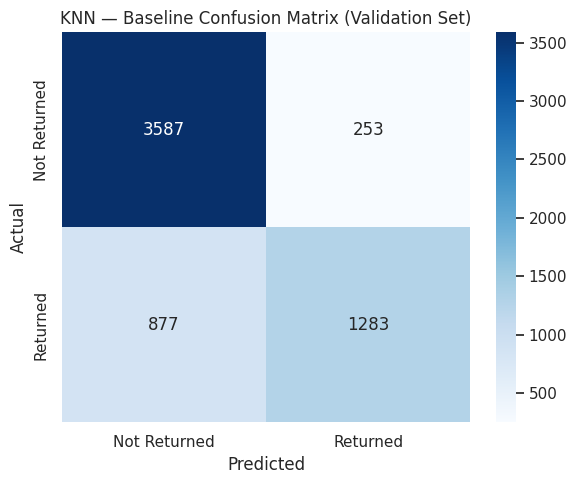

Confusion matrix [TN, FP; FN, TP]:
[[3587  253]
 [ 877 1283]]
KNN validation threshold: 0.327117
Validation precision: 0.7131
Validation recall   : 0.8194
Validation F1-score : 0.7626

KNN — VALIDATION EVALUATION AT SELECTED THRESHOLD
Accuracy    : 0.8163 (81.63%)
Precision   : 0.7131 (71.31%)
Recall      : 0.8194 (81.94%)
F1-score    : 0.7626 (76.26%)
ROC-AUC     : 0.8965 (89.65%)
PR-AUC      : 0.8353 (83.53%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.89      0.81      0.85      3840
    Returned       0.71      0.82      0.76      2160

    accuracy                           0.82      6000
   macro avg       0.80      0.82      0.81      6000
weighted avg       0.83      0.82      0.82      6000


KNN — FINAL TEST EVALUATION
Accuracy    : 0.8150 (81.50%)
Precision   : 0.7052 (70.52%)
Recall      : 0.8352 (83.52%)
F1-score    : 0.7647 (76.47%)
ROC-AUC     : 0.8974 (89.74%)
PR-AUC      : 0.8393 (83.93%)

Classification report:
 

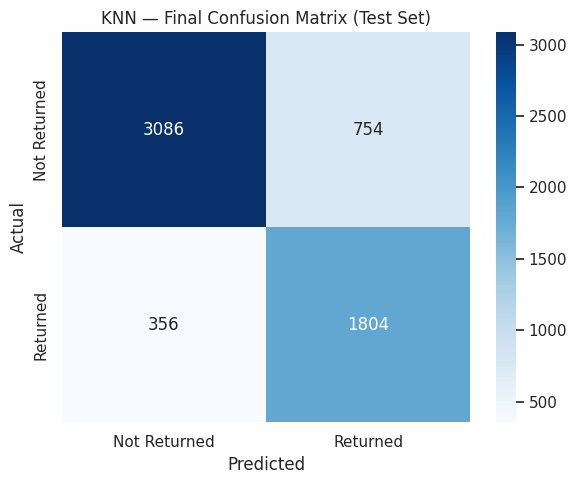

Confusion matrix [TN, FP; FN, TP]:
[[3086  754]
 [ 356 1804]]


array([[3086,  754],
       [ 356, 1804]])

In [ ]:
# ============================================================
# SECTION 10. K-NEAREST NEIGHBORS (KNN) —
# ============================================================

knn_baseline_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor(scale_numeric=True)),
    ('classifier', KNeighborsClassifier(
        n_neighbors=15,
        weights='distance',
        metric='manhattan',
        n_jobs=1
    ))
])

model_configurations['KNN'] = {
    'n_neighbors': 15,
    'weights': 'distance',
    'metric': 'manhattan'
}

# 10.2 Train the baseline model on the training set.
knn_baseline_model.fit(X_train, y_train)
knn_baseline_val_pred = knn_baseline_model.predict(X_val)
knn_baseline_val_score = get_continuous_scores(knn_baseline_model, X_val)

baseline_results['KNN'] = print_evaluation(
    'KNN — Baseline Validation Evaluation',
    y_val,
    knn_baseline_val_pred,
    knn_baseline_val_score
)

plot_confusion_matrix(
    y_val,
    knn_baseline_val_pred,
    'KNN — Baseline Confusion Matrix (Validation Set)',
    'knn_baseline_confusion_matrix.png'
)


knn_val_score = knn_baseline_val_score
(
    knn_best_threshold,
    knn_threshold_precision,
    knn_threshold_recall,
    knn_threshold_f1
) = find_best_f1_threshold(y_val, knn_val_score)
selected_thresholds['KNN'] = knn_best_threshold

print(f'KNN validation threshold: {knn_best_threshold:.6f}')
print(f'Validation precision: {knn_threshold_precision:.4f}')
print(f'Validation recall   : {knn_threshold_recall:.4f}')
print(f'Validation F1-score : {knn_threshold_f1:.4f}')

knn_val_threshold_pred = (knn_val_score >= knn_best_threshold).astype(int)
print_evaluation(
    'KNN — Validation Evaluation at Selected Threshold',
    y_val,
    knn_val_threshold_pred,
    knn_val_score
)

# 10.4 Evaluate once on the untouched test set.
knn_test_score = get_continuous_scores(knn_baseline_model, X_test)
knn_test_pred = (knn_test_score >= knn_best_threshold).astype(int)

final_models['KNN'] = knn_baseline_model
final_predictions['KNN'] = knn_test_pred
final_scores['KNN'] = knn_test_score
final_results['KNN'] = calculate_metrics(y_test, knn_test_pred, knn_test_score)
final_results['KNN']['Threshold'] = knn_best_threshold

print_evaluation(
    'KNN — Final Test Evaluation', y_test, knn_test_pred, knn_test_score
)
plot_confusion_matrix(
    y_test, knn_test_pred,
    'KNN — Final Confusion Matrix (Test Set)',
    'knn_final_confusion_matrix.png'
)


Section 11 — Decision Tree: Baseline Training and Final Evaluation



DECISION TREE — BASELINE VALIDATION EVALUATION
Accuracy    : 0.7828 (78.28%)
Precision   : 0.6987 (69.87%)
Recall      : 0.6977 (69.77%)
F1-score    : 0.6982 (69.82%)
ROC-AUC     : 0.7642 (76.42%)
PR-AUC      : 0.5963 (59.63%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.83      0.83      0.83      3840
    Returned       0.70      0.70      0.70      2160

    accuracy                           0.78      6000
   macro avg       0.76      0.76      0.76      6000
weighted avg       0.78      0.78      0.78      6000



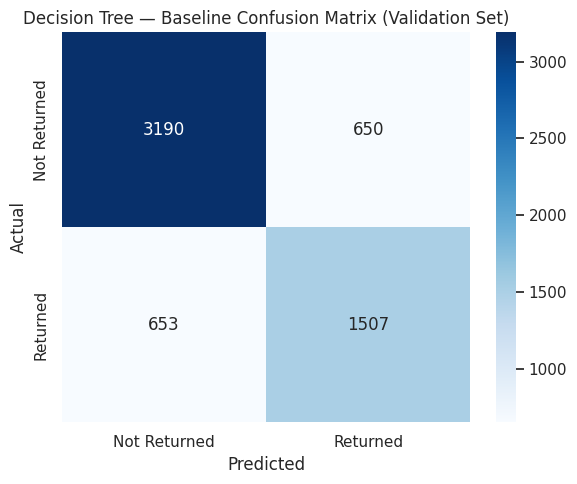

Confusion matrix [TN, FP; FN, TP]:
[[3190  650]
 [ 653 1507]]
Decision Tree validation threshold: 1.000000
Validation precision: 0.6987
Validation recall   : 0.6977
Validation F1-score : 0.6982

DECISION TREE — VALIDATION EVALUATION AT SELECTED THRESHOLD
Accuracy    : 0.7828 (78.28%)
Precision   : 0.6987 (69.87%)
Recall      : 0.6977 (69.77%)
F1-score    : 0.6982 (69.82%)
ROC-AUC     : 0.7642 (76.42%)
PR-AUC      : 0.5963 (59.63%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.83      0.83      0.83      3840
    Returned       0.70      0.70      0.70      2160

    accuracy                           0.78      6000
   macro avg       0.76      0.76      0.76      6000
weighted avg       0.78      0.78      0.78      6000


DECISION TREE — FINAL TEST EVALUATION
Accuracy    : 0.7867 (78.67%)
Precision   : 0.7031 (70.31%)
Recall      : 0.7051 (70.51%)
F1-score    : 0.7041 (70.41%)
ROC-AUC     : 0.7688 (76.88%)
PR-AUC      : 0.6019 (60.

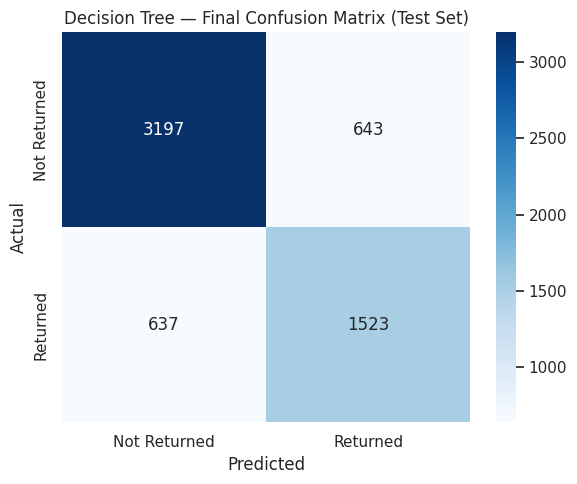

Confusion matrix [TN, FP; FN, TP]:
[[3197  643]
 [ 637 1523]]


array([[3197,  643],
       [ 637, 1523]])

In [ ]:
# ============================================================
# SECTION 11. DECISION TREE
# ============================================================


decision_tree_baseline_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor(scale_numeric=False)),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=RANDOM_STATE
    ))
])

model_configurations['Decision Tree'] = {
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1
}

# 11.2 Train and evaluate the baseline model on validation data.
decision_tree_baseline_model.fit(X_train, y_train)
decision_tree_baseline_val_pred = decision_tree_baseline_model.predict(X_val)
decision_tree_baseline_val_score = get_continuous_scores(
    decision_tree_baseline_model, X_val
)

baseline_results['Decision Tree'] = print_evaluation(
    'Decision Tree — Baseline Validation Evaluation',
    y_val,
    decision_tree_baseline_val_pred,
    decision_tree_baseline_val_score
)
plot_confusion_matrix(
    y_val, decision_tree_baseline_val_pred,
    'Decision Tree — Baseline Confusion Matrix (Validation Set)',
    'decision_tree_baseline_confusion_matrix.png'
)

# 11.3 Select the classification threshold using validation scores only.
decision_tree_val_score = decision_tree_baseline_val_score
(
    decision_tree_best_threshold,
    decision_tree_threshold_precision,
    decision_tree_threshold_recall,
    decision_tree_threshold_f1
) = find_best_f1_threshold(y_val, decision_tree_val_score)
selected_thresholds['Decision Tree'] = decision_tree_best_threshold

print(f'Decision Tree validation threshold: {decision_tree_best_threshold:.6f}')
print(f'Validation precision: {decision_tree_threshold_precision:.4f}')
print(f'Validation recall   : {decision_tree_threshold_recall:.4f}')
print(f'Validation F1-score : {decision_tree_threshold_f1:.4f}')

decision_tree_val_threshold_pred = (
    decision_tree_val_score >= decision_tree_best_threshold
).astype(int)
print_evaluation(
    'Decision Tree — Validation Evaluation at Selected Threshold',
    y_val, decision_tree_val_threshold_pred, decision_tree_val_score
)

# 11.4 Final evaluation on the untouched test set.
decision_tree_test_score = get_continuous_scores(decision_tree_baseline_model, X_test)
decision_tree_test_pred = (
    decision_tree_test_score >= decision_tree_best_threshold
).astype(int)

final_models['Decision Tree'] = decision_tree_baseline_model
final_predictions['Decision Tree'] = decision_tree_test_pred
final_scores['Decision Tree'] = decision_tree_test_score
final_results['Decision Tree'] = calculate_metrics(
    y_test, decision_tree_test_pred, decision_tree_test_score
)
final_results['Decision Tree']['Threshold'] = decision_tree_best_threshold

print_evaluation(
    'Decision Tree — Final Test Evaluation',
    y_test, decision_tree_test_pred, decision_tree_test_score
)
plot_confusion_matrix(
    y_test, decision_tree_test_pred,
    'Decision Tree — Final Confusion Matrix (Test Set)',
    'decision_tree_final_confusion_matrix.png'
)


Section 12 — Random Forest: Baseline Training and Final Evaluation



RANDOM FOREST — BASELINE VALIDATION EVALUATION
Accuracy    : 0.8397 (83.97%)
Precision   : 0.8069 (80.69%)
Recall      : 0.7292 (72.92%)
F1-score    : 0.7661 (76.61%)
ROC-AUC     : 0.9189 (91.89%)
PR-AUC      : 0.8653 (86.53%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.86      0.90      0.88      3840
    Returned       0.81      0.73      0.77      2160

    accuracy                           0.84      6000
   macro avg       0.83      0.82      0.82      6000
weighted avg       0.84      0.84      0.84      6000



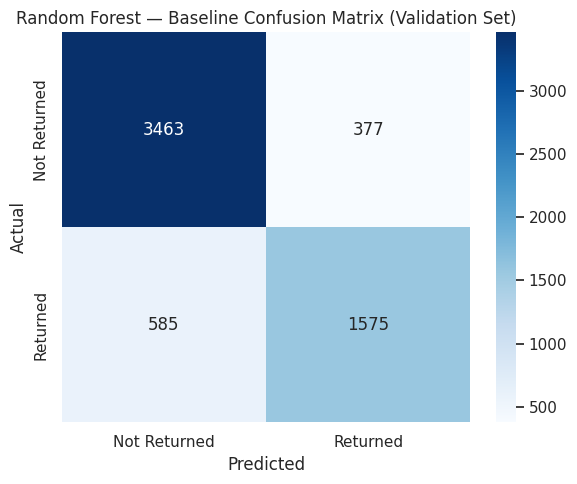

Confusion matrix [TN, FP; FN, TP]:
[[3463  377]
 [ 585 1575]]
Random Forest validation threshold: 0.360000
Validation precision: 0.7277
Validation recall   : 0.8523
Validation F1-score : 0.7851

RANDOM FOREST — VALIDATION EVALUATION AT SELECTED THRESHOLD
Accuracy    : 0.8320 (83.20%)
Precision   : 0.7277 (72.77%)
Recall      : 0.8523 (85.23%)
F1-score    : 0.7851 (78.51%)
ROC-AUC     : 0.9189 (91.89%)
PR-AUC      : 0.8653 (86.53%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.91      0.82      0.86      3840
    Returned       0.73      0.85      0.79      2160

    accuracy                           0.83      6000
   macro avg       0.82      0.84      0.82      6000
weighted avg       0.84      0.83      0.83      6000


RANDOM FOREST — FINAL TEST EVALUATION
Accuracy    : 0.8288 (82.88%)
Precision   : 0.7195 (71.95%)
Recall      : 0.8597 (85.97%)
F1-score    : 0.7834 (78.34%)
ROC-AUC     : 0.9162 (91.62%)
PR-AUC      : 0.8672 (86.

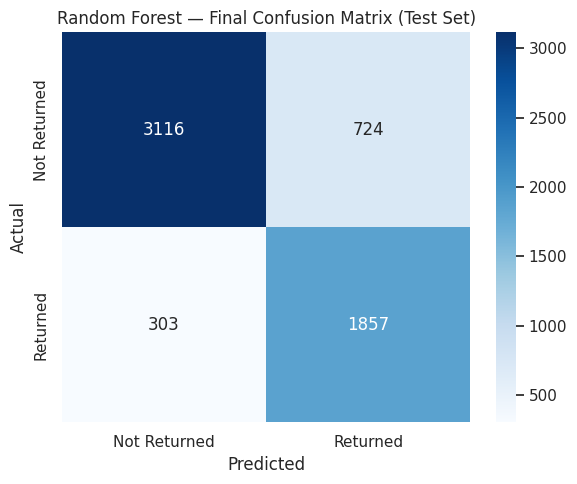

Confusion matrix [TN, FP; FN, TP]:
[[3116  724]
 [ 303 1857]]


array([[3116,  724],
       [ 303, 1857]])

In [ ]:
# ============================================================
# SECTION 12. RANDOM FOREST
# ============================================================


random_forest_baseline_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor(scale_numeric=False)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        max_depth=None,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model_configurations['Random Forest'] = {
    'n_estimators': 100,
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_leaf': 1,
    'max_features': 'sqrt'
}

# 12.2 Train and evaluate the baseline model on validation data.
random_forest_baseline_model.fit(X_train, y_train)
random_forest_baseline_val_pred = random_forest_baseline_model.predict(X_val)
random_forest_baseline_val_score = get_continuous_scores(
    random_forest_baseline_model, X_val
)

baseline_results['Random Forest'] = print_evaluation(
    'Random Forest — Baseline Validation Evaluation',
    y_val,
    random_forest_baseline_val_pred,
    random_forest_baseline_val_score
)
plot_confusion_matrix(
    y_val, random_forest_baseline_val_pred,
    'Random Forest — Baseline Confusion Matrix (Validation Set)',
    'random_forest_baseline_confusion_matrix.png'
)

# 12.3 Select the classification threshold using validation scores only.
random_forest_val_score = random_forest_baseline_val_score
(
    random_forest_best_threshold,
    random_forest_threshold_precision,
    random_forest_threshold_recall,
    random_forest_threshold_f1
) = find_best_f1_threshold(y_val, random_forest_val_score)
selected_thresholds['Random Forest'] = random_forest_best_threshold

print(f'Random Forest validation threshold: {random_forest_best_threshold:.6f}')
print(f'Validation precision: {random_forest_threshold_precision:.4f}')
print(f'Validation recall   : {random_forest_threshold_recall:.4f}')
print(f'Validation F1-score : {random_forest_threshold_f1:.4f}')

random_forest_val_threshold_pred = (
    random_forest_val_score >= random_forest_best_threshold
).astype(int)
print_evaluation(
    'Random Forest — Validation Evaluation at Selected Threshold',
    y_val, random_forest_val_threshold_pred, random_forest_val_score
)

# 12.4 Final evaluation on the untouched test set.
random_forest_test_score = get_continuous_scores(random_forest_baseline_model, X_test)
random_forest_test_pred = (
    random_forest_test_score >= random_forest_best_threshold
).astype(int)

final_models['Random Forest'] = random_forest_baseline_model
final_predictions['Random Forest'] = random_forest_test_pred
final_scores['Random Forest'] = random_forest_test_score
final_results['Random Forest'] = calculate_metrics(
    y_test, random_forest_test_pred, random_forest_test_score
)
final_results['Random Forest']['Threshold'] = random_forest_best_threshold

print_evaluation(
    'Random Forest — Final Test Evaluation',
    y_test, random_forest_test_pred, random_forest_test_score
)
plot_confusion_matrix(
    y_test, random_forest_test_pred,
    'Random Forest — Final Confusion Matrix (Test Set)',
    'random_forest_final_confusion_matrix.png'
)


Section 13 — SVM: Baseline Training and Final Evaluation



SVM — BASELINE VALIDATION EVALUATION
Accuracy    : 0.8540 (85.40%)
Precision   : 0.8129 (81.29%)
Recall      : 0.7722 (77.22%)
F1-score    : 0.7920 (79.20%)
ROC-AUC     : 0.9325 (93.25%)
PR-AUC      : 0.8928 (89.28%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.88      0.90      0.89      3840
    Returned       0.81      0.77      0.79      2160

    accuracy                           0.85      6000
   macro avg       0.84      0.84      0.84      6000
weighted avg       0.85      0.85      0.85      6000



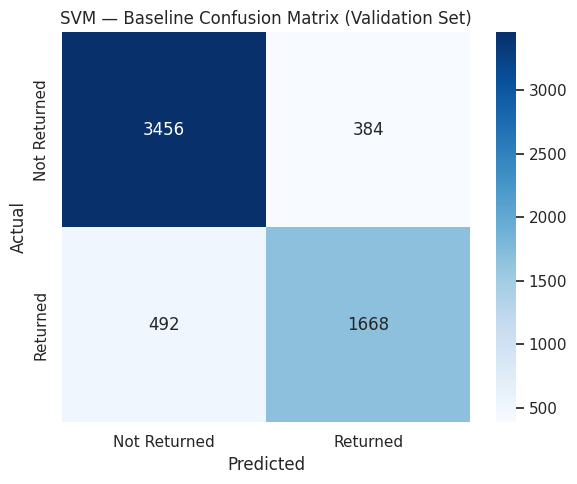

Confusion matrix [TN, FP; FN, TP]:
[[3456  384]
 [ 492 1668]]
SVM validation decision threshold: -0.102455
Validation precision: 0.7858
Validation recall   : 0.8171
Validation F1-score : 0.8012

SVM — VALIDATION EVALUATION AT SELECTED THRESHOLD
Accuracy    : 0.8540 (85.40%)
Precision   : 0.7858 (78.58%)
Recall      : 0.8171 (81.71%)
F1-score    : 0.8012 (80.12%)
ROC-AUC     : 0.9325 (93.25%)
PR-AUC      : 0.8928 (89.28%)

Classification report:
              precision    recall  f1-score   support

Not Returned       0.89      0.87      0.88      3840
    Returned       0.79      0.82      0.80      2160

    accuracy                           0.85      6000
   macro avg       0.84      0.85      0.84      6000
weighted avg       0.86      0.85      0.85      6000


SVM — FINAL TEST EVALUATION
Accuracy    : 0.8570 (85.70%)
Precision   : 0.7891 (78.91%)
Recall      : 0.8227 (82.27%)
F1-score    : 0.8055 (80.55%)
ROC-AUC     : 0.9321 (93.21%)
PR-AUC      : 0.8956 (89.56%)

Classification

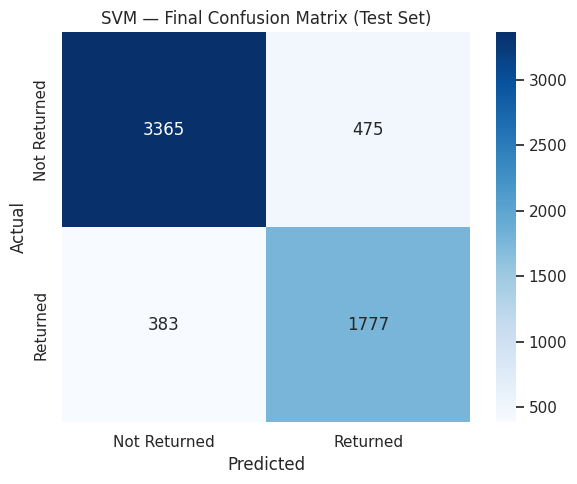

Confusion matrix [TN, FP; FN, TP]:
[[3365  475]
 [ 383 1777]]


array([[3365,  475],
       [ 383, 1777]])

In [ ]:
# ============================================================
# SECTION 13. SUPPORT VECTOR MACHINE (SVM)
# ============================================================


svm_baseline_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor(scale_numeric=True)),
    ('classifier', LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=20000,
        random_state=RANDOM_STATE
    ))
])

model_configurations['SVM'] = {
    'kernel': 'linear (LinearSVC)',
    'C': 1.0,
    'class_weight': None,
    'max_iter': 20000
}

# 13.2 Train and evaluate the baseline model on validation data.
svm_baseline_model.fit(X_train, y_train)
svm_baseline_val_pred = svm_baseline_model.predict(X_val)
svm_baseline_val_score = get_continuous_scores(svm_baseline_model, X_val)

baseline_results['SVM'] = print_evaluation(
    'SVM — Baseline Validation Evaluation',
    y_val,
    svm_baseline_val_pred,
    svm_baseline_val_score
)
plot_confusion_matrix(
    y_val, svm_baseline_val_pred,
    'SVM — Baseline Confusion Matrix (Validation Set)',
    'svm_baseline_confusion_matrix.png'
)

# 13.3 Select the classification threshold using validation decision scores only.
svm_val_score = svm_baseline_val_score
(
    svm_best_threshold,
    svm_threshold_precision,
    svm_threshold_recall,
    svm_threshold_f1
) = find_best_f1_threshold(y_val, svm_val_score)
selected_thresholds['SVM'] = svm_best_threshold

print(f'SVM validation decision threshold: {svm_best_threshold:.6f}')
print(f'Validation precision: {svm_threshold_precision:.4f}')
print(f'Validation recall   : {svm_threshold_recall:.4f}')
print(f'Validation F1-score : {svm_threshold_f1:.4f}')

svm_val_threshold_pred = (svm_val_score >= svm_best_threshold).astype(int)
print_evaluation(
    'SVM — Validation Evaluation at Selected Threshold',
    y_val, svm_val_threshold_pred, svm_val_score
)

# 13.4 Final evaluation on the untouched test set.
svm_test_score = get_continuous_scores(svm_baseline_model, X_test)
svm_test_pred = (svm_test_score >= svm_best_threshold).astype(int)

final_models['SVM'] = svm_baseline_model
final_predictions['SVM'] = svm_test_pred
final_scores['SVM'] = svm_test_score
final_results['SVM'] = calculate_metrics(y_test, svm_test_pred, svm_test_score)
final_results['SVM']['Threshold'] = svm_best_threshold

print_evaluation('SVM — Final Test Evaluation', y_test, svm_test_pred, svm_test_score)
plot_confusion_matrix(
    y_test, svm_test_pred,
    'SVM — Final Confusion Matrix (Test Set)',
    'svm_final_confusion_matrix.png'
)


Section 14 — Final Comparison of the Four Algorithms


In [ ]:
# ============================================================
# SECTION 14. FINAL FOUR-ALGORITHM COMPARISON
# ============================================================

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'PR-AUC']
comparison_df = pd.DataFrame.from_dict(final_results, orient='index')
comparison_df.index.name = 'Algorithm'
comparison_display = comparison_df.copy()
comparison_display[metric_columns] = comparison_display[metric_columns] * 100
comparison_display = comparison_display.sort_values('F1-score', ascending=False)

print('BASELINE MODEL COMPARISON — HELD-OUT TEST SET')
display(comparison_display.round(2))
comparison_df.to_csv(OUTPUT_DIR / 'four_algorithm_comparison.csv')

print('\nBest model by F1-score:', comparison_df['F1-score'].idxmax())
print('Best model by accuracy:', comparison_df['Accuracy'].idxmax())
print('Best model by ROC-AUC:', comparison_df['ROC-AUC'].idxmax())
print('Best model by PR-AUC:', comparison_df['PR-AUC'].idxmax())


BASELINE MODEL COMPARISON — HELD-OUT TEST SET


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Threshold
Algorithm,,,,,,,
SVM,85.70,78.91,82.27,80.55,93.21,89.56,-0.10
Random Forest,82.88,71.95,85.97,78.34,91.62,86.72,0.36
KNN,81.50,70.52,83.52,76.47,89.74,83.93,0.33
Decision Tree,78.67,70.31,70.51,70.41,76.88,60.19,1.00



Best model by F1-score: SVM
Best model by accuracy: SVM
Best model by ROC-AUC: SVM
Best model by PR-AUC: SVM


Section 14.1 — Grouped Model Metric Comparison Chart


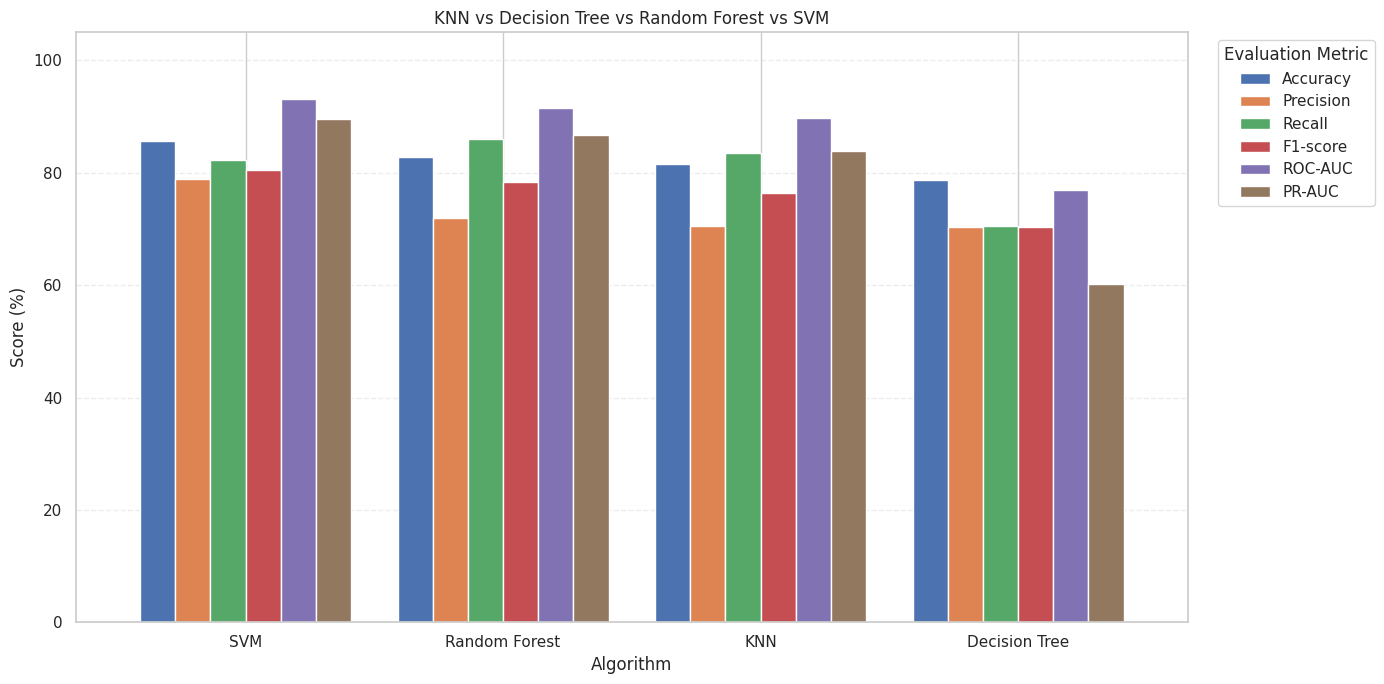

In [ ]:
# ============================================================
# SECTION 14.1. GROUPED MODEL COMPARISON CHART
# ============================================================

comparison_plot = comparison_df[metric_columns].sort_values('F1-score', ascending=False) * 100
ax = comparison_plot.plot(kind='bar', figsize=(14, 7), width=0.82)
plt.title('KNN vs Decision Tree vs Random Forest vs SVM')
plt.xlabel('Algorithm')
plt.ylabel('Score (%)')
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'four_algorithm_metric_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()


Section 14.2 — Separate Accuracy and F1-Score Charts


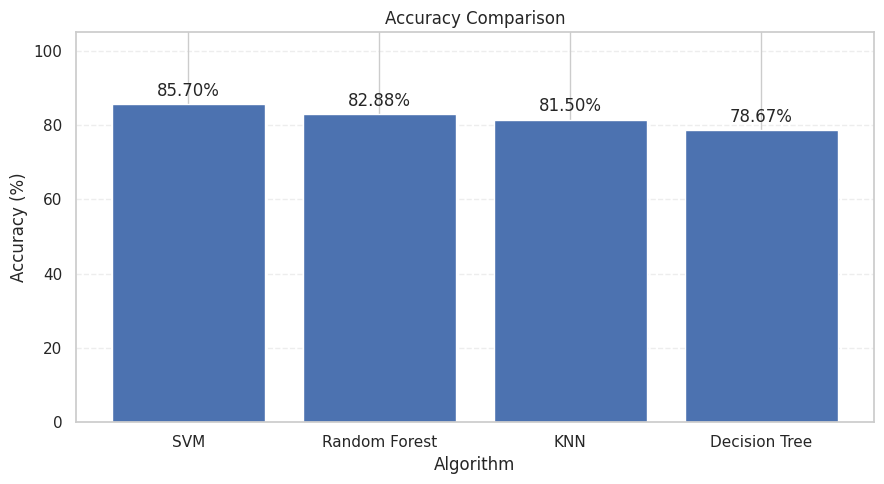

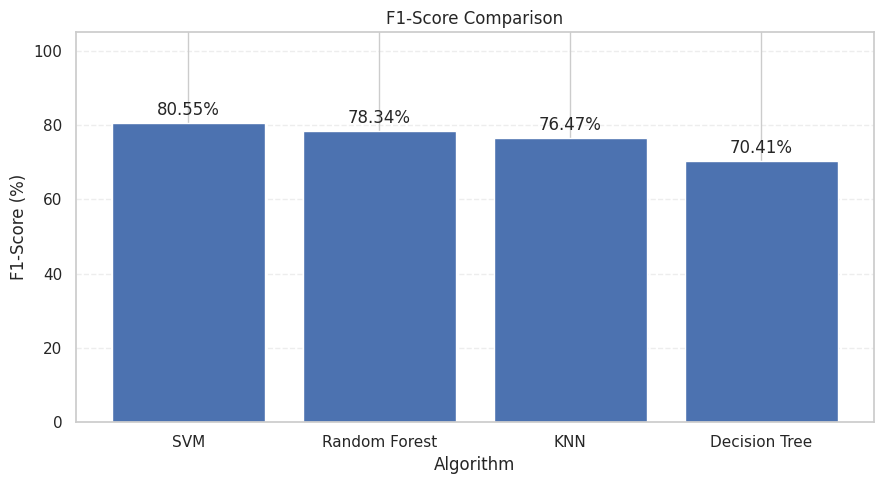

In [ ]:
# ============================================================
# SECTION 14.2. ACCURACY AND F1-SCORE COMPARISON CHARTS
# ============================================================

accuracy_plot = comparison_df['Accuracy'].sort_values(ascending=False) * 100
plt.figure(figsize=(9, 5))
bars = plt.bar(accuracy_plot.index, accuracy_plot.values)
plt.bar_label(bars, fmt='%.2f%%', padding=3)
plt.title('Accuracy Comparison')
plt.xlabel('Algorithm')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
f1_plot = comparison_df['F1-score'].sort_values(ascending=False) * 100
plt.figure(figsize=(9, 5))
bars = plt.bar(f1_plot.index, f1_plot.values)
plt.bar_label(bars, fmt='%.2f%%', padding=3)
plt.title('F1-Score Comparison')
plt.xlabel('Algorithm')
plt.ylabel('F1-Score (%)')
plt.ylim(0, 105)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_score_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()


Section 15 — Feature Importance and Feature Influence


Decision Tree — top 20 features:


,importance
numeric__product_quality_score,0.331179
numeric__product_rating,0.053659
categorical__size_fit_risk_Not Applicable,0.048808
numeric__customer_previous_return_rate_pct,0.047872
numeric__product_defect_rate_pct,0.042279
numeric__description_match_score,0.040766
numeric__image_accuracy_score,0.031956
numeric__packaging_quality_score,0.022912
numeric__shipping_cost,0.020921
numeric__product_weight_kg,0.020284


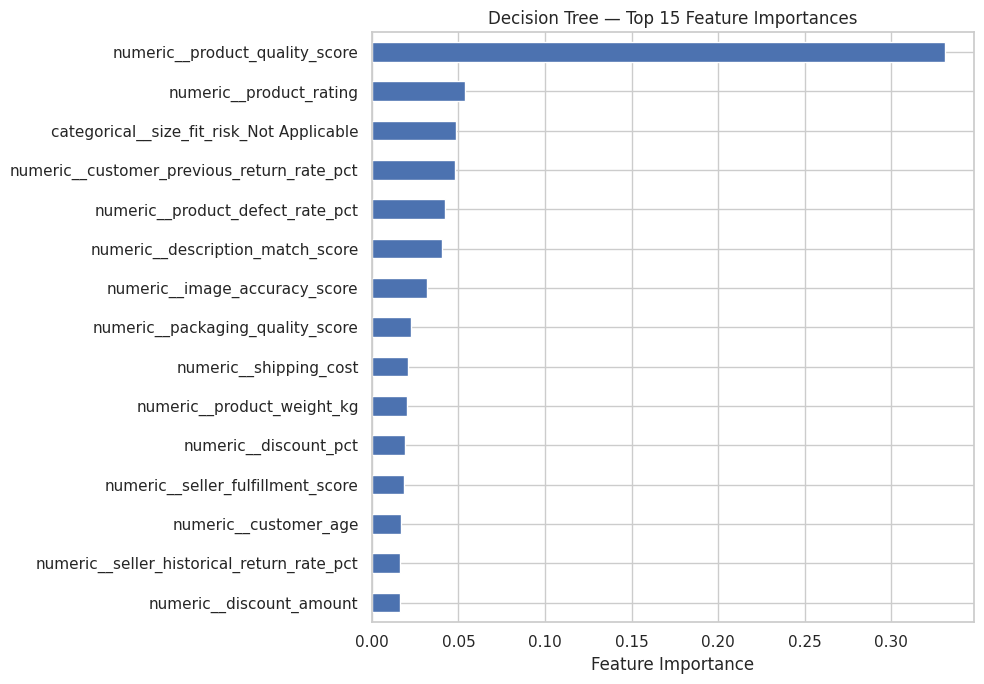

Random Forest — top 20 features:


,importance
numeric__product_quality_score,0.112772
numeric__product_rating,0.080277
numeric__product_defect_rate_pct,0.077255
numeric__description_match_score,0.049254
numeric__image_accuracy_score,0.047822
categorical__product_review_sentiment_Positive,0.038344
numeric__customer_previous_return_rate_pct,0.028263
categorical__product_review_sentiment_Neutral,0.026962
numeric__seller_historical_return_rate_pct,0.018218
numeric__seller_fulfillment_score,0.018134


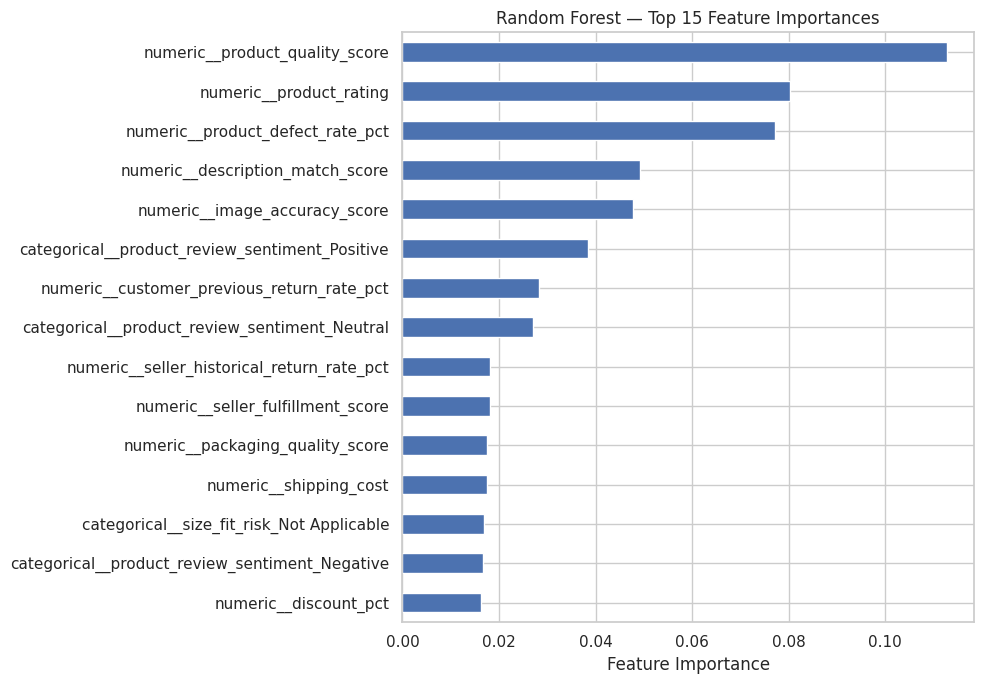

SVM — top 20 features by absolute coefficient:


,feature,coefficient,absolute_weight
147,categorical__size_fit_risk_High,0.550522,0.550522
144,categorical__product_review_sentiment_Negative,0.511166,0.511166
146,categorical__product_review_sentiment_Positive,-0.470622,0.470622
150,categorical__size_fit_risk_Not Applicable,-0.356286,0.356286
57,categorical__subcategory_Carriers,-0.299232,0.299232
12,numeric__product_defect_rate_pct,0.287460,0.287460
36,categorical__category_Footwear,0.269342,0.269342
148,categorical__size_fit_risk_Low,-0.267412,0.267412
35,categorical__category_Fashion,0.267237,0.267237
13,numeric__description_match_score,-0.259070,0.259070


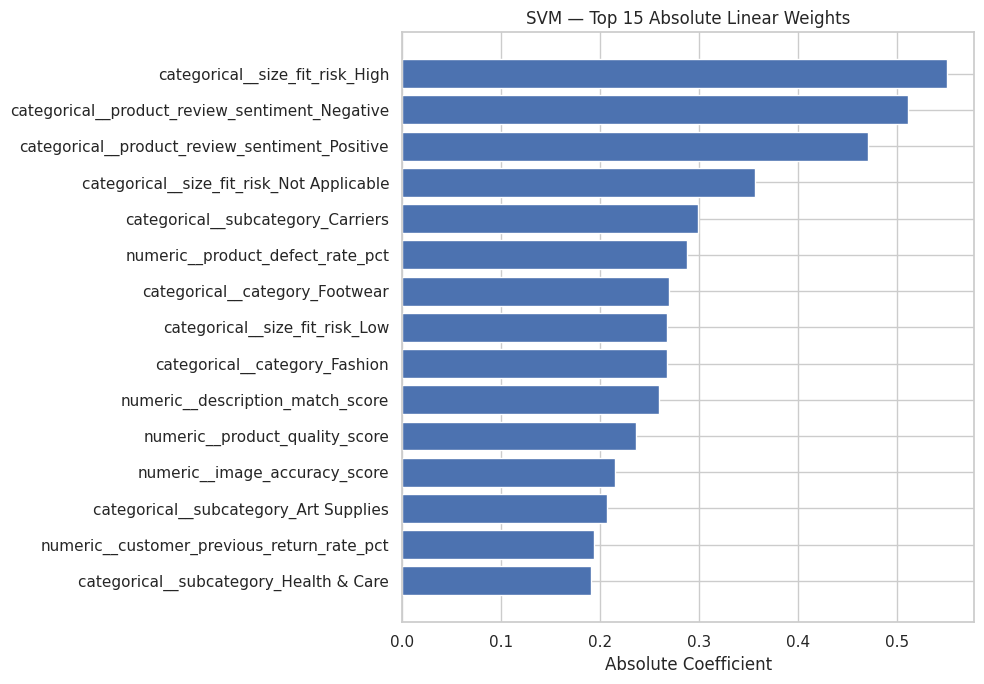

KNN — top 15 permutation importances:


,mean_change_in_PR_AUC
product_review_sentiment,0.036732
product_rating,0.028488
product_defect_rate_pct,0.028459
product_quality_score,0.027069
seller_fulfillment_score,0.020098
customer_previous_return_rate_pct,0.019699
seller_rating,0.017925
order_weekday_cos,0.015133
seller_historical_return_rate_pct,0.013579
image_accuracy_score,0.013338


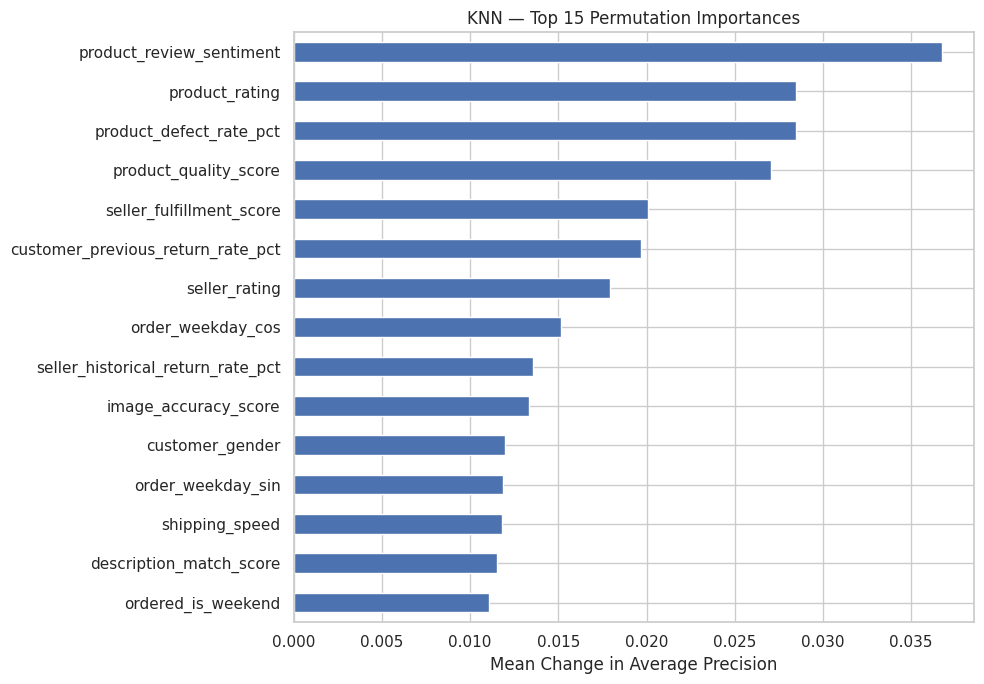

In [ ]:
# ============================================================
# SECTION 15. FEATURE IMPORTANCE AND FEATURE INFLUENCE
# ============================================================

# 15.1 Decision Tree feature importance.
dt_preprocessor = final_models['Decision Tree'].named_steps['preprocessor']
dt_classifier = final_models['Decision Tree'].named_steps['classifier']
dt_feature_names = dt_preprocessor.get_feature_names_out()
dt_importance = pd.Series(dt_classifier.feature_importances_, index=dt_feature_names).sort_values(ascending=False)
print('Decision Tree — top 20 features:')
display(dt_importance.head(20).to_frame('importance'))
plt.figure(figsize=(10, 7))
dt_importance.head(15).sort_values().plot(kind='barh')
plt.title('Decision Tree — Top 15 Feature Importances')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'decision_tree_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
# 15.2 Random Forest feature importance.
rf_preprocessor = final_models['Random Forest'].named_steps['preprocessor']
rf_classifier = final_models['Random Forest'].named_steps['classifier']
rf_feature_names = rf_preprocessor.get_feature_names_out()
rf_importance = pd.Series(rf_classifier.feature_importances_, index=rf_feature_names).sort_values(ascending=False)
print('Random Forest — top 20 features:')
display(rf_importance.head(20).to_frame('importance'))
plt.figure(figsize=(10, 7))
rf_importance.head(15).sort_values().plot(kind='barh')
plt.title('Random Forest — Top 15 Feature Importances')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'random_forest_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
# 15.3 Linear SVM coefficient magnitudes. Absolute magnitude gives influence size,
# while coefficient sign indicates direction for the positive class in this binary model.
svm_preprocessor = final_models['SVM'].named_steps['preprocessor']
svm_classifier = final_models['SVM'].named_steps['classifier']
svm_feature_names = svm_preprocessor.get_feature_names_out()
svm_coefficients = svm_classifier.coef_.ravel()
svm_weights = pd.DataFrame({
    'feature': svm_feature_names,
    'coefficient': svm_coefficients,
    'absolute_weight': np.abs(svm_coefficients)
}).sort_values('absolute_weight', ascending=False)
print('SVM — top 20 features by absolute coefficient:')
display(svm_weights.head(20))
plt.figure(figsize=(10, 7))
svm_top = svm_weights.head(15).sort_values('absolute_weight')
plt.barh(svm_top['feature'], svm_top['absolute_weight'])
plt.title('SVM — Top 15 Absolute Linear Weights')
plt.xlabel('Absolute Coefficient')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'svm_feature_weights.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
# 15.4 KNN has no native feature_importances_ attribute, so estimate permutation importance.
# A small validation sample keeps the calculation manageable.
knn_sample_size = min(300, len(X_val))
knn_X_sample = X_val.sample(n=knn_sample_size, random_state=RANDOM_STATE)
knn_y_sample = y_val.loc[knn_X_sample.index]
knn_permutation = permutation_importance(
    final_models['KNN'], knn_X_sample, knn_y_sample,
    scoring='average_precision', n_repeats=2,
    random_state=RANDOM_STATE, n_jobs=1
)
knn_importance = pd.Series(knn_permutation.importances_mean, index=X_val.columns).sort_values(ascending=False)
print('KNN — top 15 permutation importances:')
display(knn_importance.head(15).to_frame('mean_change_in_PR_AUC'))
plt.figure(figsize=(10, 7))
knn_importance.head(15).sort_values().plot(kind='barh')
plt.title('KNN — Top 15 Permutation Importances')
plt.xlabel('Mean Change in Average Precision')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'knn_permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
# Export importance tables.
pd.DataFrame({'feature': dt_importance.index, 'importance': dt_importance.values}).to_csv(OUTPUT_DIR / 'decision_tree_feature_importance.csv', index=False)
pd.DataFrame({'feature': rf_importance.index, 'importance': rf_importance.values}).to_csv(OUTPUT_DIR / 'random_forest_feature_importance.csv', index=False)
svm_weights.to_csv(OUTPUT_DIR / 'svm_feature_weights.csv', index=False)
pd.DataFrame({'feature': knn_importance.index, 'importance': knn_importance.values}).to_csv(OUTPUT_DIR / 'knn_permutation_importance.csv', index=False)


Section 17 — Prepare Data for Return-Reason Classification


Rows available for return-reason classification: 10800
Reason classes: ['Defective', 'Missing/Wrong item', 'No longer needed', 'Not as described', 'Slow delivery']

Reason counts:


,count
return_reason,
Defective,3038
No longer needed,2699
Not as described,2509
Missing/Wrong item,1819
Slow delivery,735



Reason percentages:


,percentage
return_reason,
Defective,28.13
No longer needed,24.99
Not as described,23.23
Missing/Wrong item,16.84
Slow delivery,6.81


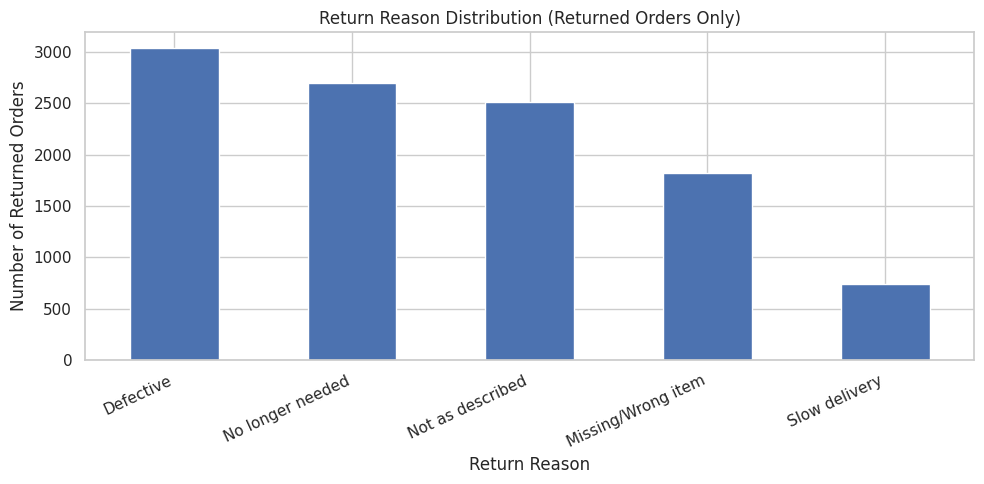

Reason model training shape: (8640, 46)
Reason model testing shape: (2160, 46)


In [ ]:
# ============================================================
# SECTION 17. PREPARE RETURN-REASON DATASET
# ============================================================

# This model is trained only on records where returned=1 and the reason is known.
returned_rows = df.loc[df['returned'].eq(1)].copy()
if returned_rows.empty:
    raise ValueError('No returned records available for reason classification.')
if returned_rows['return_reason'].isna().any():
    raise ValueError('Some returned records have no return_reason.')

X_reason = returned_rows.drop(columns=['returned', 'return_reason']).copy()
y_reason = returned_rows['return_reason'].astype(str).copy()

# Ensure reason features match the binary model's feature columns, in the same order.
X_reason = X_reason.reindex(columns=X.columns)
reason_classes = sorted(y_reason.unique().tolist())
print('Rows available for return-reason classification:', len(X_reason))
print('Reason classes:', reason_classes)
print('\nReason counts:')
display(y_reason.value_counts().to_frame('count'))
print('\nReason percentages:')
display((y_reason.value_counts(normalize=True) * 100).round(2).to_frame('percentage'))

plt.figure(figsize=(10, 5))
y_reason.value_counts().plot(kind='bar')
plt.title('Return Reason Distribution (Returned Orders Only)')
plt.xlabel('Return Reason')
plt.ylabel('Number of Returned Orders')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'reason_classification_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
X_reason_train, X_reason_test, y_reason_train, y_reason_test = train_test_split(
    X_reason, y_reason,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_reason
)
print('Reason model training shape:', X_reason_train.shape)
print('Reason model testing shape:', X_reason_test.shape)


Section 18 — Return-Reason Classifier: Baseline Random Forest


Baseline reason model trained.

Baseline reason classification report:
                    precision    recall  f1-score   support

         Defective       0.58      0.69      0.63       607
Missing/Wrong item       0.61      0.31      0.41       364
  No longer needed       0.48      0.58      0.53       540
  Not as described       0.56      0.51      0.53       502
     Slow delivery       0.49      0.51      0.50       147

          accuracy                           0.54      2160
         macro avg       0.54      0.52      0.52      2160
      weighted avg       0.55      0.54      0.54      2160



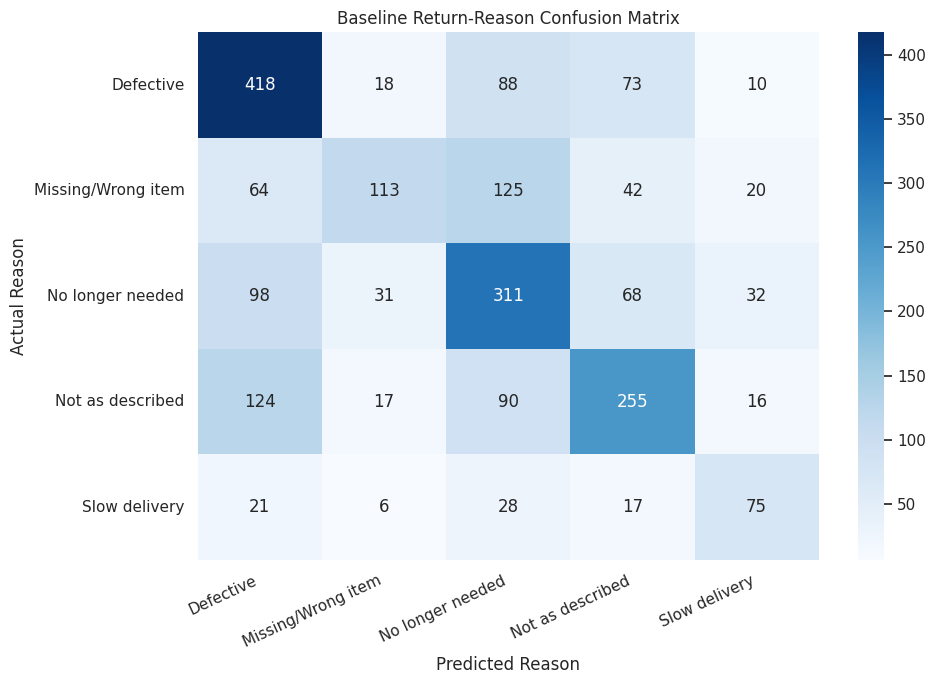

In [ ]:
# ============================================================
# SECTION 18. BASELINE RETURN-REASON CLASSIFIER
# ============================================================

reason_baseline_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor(scale_numeric=False)),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        class_weight='balanced_subsample',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

reason_baseline_model.fit(X_reason_train, y_reason_train)
reason_baseline_pred = reason_baseline_model.predict(X_reason_test)

print('Baseline reason model trained.')
print('\nBaseline reason classification report:')
print(classification_report(
    y_reason_test, reason_baseline_pred,
    labels=reason_classes, zero_division=0
))
reason_baseline_cm = confusion_matrix(y_reason_test, reason_baseline_pred, labels=reason_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(reason_baseline_cm, annot=True, fmt='d', cmap='Blues', xticklabels=reason_classes, yticklabels=reason_classes)
plt.title('Baseline Return-Reason Confusion Matrix')
plt.xlabel('Predicted Reason')
plt.ylabel('Actual Reason')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'reason_baseline_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()


Section 19 — Return-Reason Classifier: Baseline Model


In [ ]:
# ============================================================
# SECTION 19. RETURN-REASON CLASSIFIER — NO HYPERPARAMETER TUNING
# ============================================================

# Reuse the baseline Random Forest trained in Section 18.
# Its settings are explicit and fixed; no grid search or CV search is run.
reason_model = reason_baseline_model
reason_model_configuration = {
    'estimator': 'RandomForestClassifier',
    'n_estimators': 150,
    'class_weight': 'balanced_subsample',
    'random_state': RANDOM_STATE
}

print('Return-reason model: baseline Random Forest (no hyperparameter tuning).')
print('Model configuration:')
print(reason_model_configuration)


Return-reason model: baseline Random Forest (no hyperparameter tuning).
Model configuration:
{'estimator': 'RandomForestClassifier', 'n_estimators': 150, 'class_weight': 'balanced_subsample', 'random_state': 42}


Section 22 — Save Models, Metrics, and Feature Metadata


In [ ]:
# ============================================================
# SECTION 22. SAVE MODELS AND EVALUATION ARTIFACTS
# ============================================================

comparison_export = comparison_df.to_dict(orient='index')
model_bundle = {
    'project_name': 'E-Commerce Product Return Prediction and Reason Analysis',
    'target_mapping': {'Not Returned': 0, 'Returned': 1},
    'models': final_models,
    'thresholds': selected_thresholds,
    'feature_columns': X.columns.tolist(),
    'model_configurations': model_configurations,
    'comparison_results': comparison_export,
    'reason_model': reason_model,
    'reason_classes': reason_classes,
    'reason_feature_columns': X_reason.columns.tolist(),
    'reason_model_configuration': reason_model_configuration,
    'reason_test_metrics': {
        'accuracy': float(reason_accuracy),
        'macro_f1': float(reason_macro_f1),
        'weighted_f1': float(reason_weighted_f1)
    },
    'data_note': 'The 64/36 return target distribution and return_reason labels are synthetic; metrics are experimental, not verified real-world performance.'
}

bundle_path = OUTPUT_DIR / 'return_prediction_model_bundle.joblib'
joblib.dump(model_bundle, bundle_path)

comparison_df.to_csv(OUTPUT_DIR / 'four_algorithm_comparison.csv')
pd.DataFrame([
    {'algorithm': name, 'threshold': threshold}
    for name, threshold in selected_thresholds.items()
]).to_csv(OUTPUT_DIR / 'selected_thresholds.csv', index=False)

print('Saved model bundle:', bundle_path)
print('Model keys:', list(final_models.keys()))
print('Reason model classes:', reason_classes)


Saved model bundle: return_prediction_outputs/return_prediction_model_bundle.joblib
Model keys: ['KNN', 'Decision Tree', 'Random Forest', 'SVM']
Reason model classes: ['Defective', 'Missing/Wrong item', 'No longer needed', 'Not as described', 'Slow delivery']


Section 23 — Zip and Download All Outputs


In [ ]:
# ============================================================
# SECTION 23. PACKAGE AND DOWNLOAD OUTPUTS
# ============================================================

# Bundle includes joblib models, comparison tables, reports, importance tables, and charts.
zip_path = shutil.make_archive('return_prediction_outputs', 'zip', root_dir=OUTPUT_DIR)
print('Created output ZIP:', zip_path)
print('\nFiles generated:')
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print('-', file_path.name)

# Download the model bundle separately for a Streamlit dashboard.
files.download(zip_path)
files.download(str(bundle_path))


Created output ZIP: /content/return_prediction_outputs.zip

Files generated:
- accuracy_comparison.png
- boxplot_customer_previous_return_rate_pct.png
- boxplot_description_match_score.png
- boxplot_discount_pct.png
- boxplot_estimated_delivery_days.png
- boxplot_image_accuracy_score.png
- boxplot_price.png
- boxplot_product_quality_score.png
- boxplot_product_rating.png
- boxplot_seller_rating.png
- decision_tree_baseline_confusion_matrix.png
- decision_tree_feature_importance.csv
- decision_tree_feature_importance.png
- decision_tree_final_confusion_matrix.png
- f1_score_comparison.png
- four_algorithm_comparison.csv
- four_algorithm_metric_comparison.png
- initial_target_and_reason_distribution.png
- knn_baseline_confusion_matrix.png
- knn_final_confusion_matrix.png
- knn_permutation_importance.csv
- knn_permutation_importance.png
- random_forest_baseline_confusion_matrix.png
- random_forest_feature_importance.csv
- random_forest_feature_importance.png
- random_forest_final_confusio

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>